In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project dataset location
DATA_PATH = Path("../Dataset")

# Load both datasets
math_df = pd.read_csv(DATA_PATH / "student-mat.csv", sep=";")
portuguese_df = pd.read_csv(DATA_PATH / "student-por.csv", sep=";")

print("Mathematics Dataset:", math_df.shape)
print("Portuguese Dataset:", portuguese_df.shape)

display(math_df.head())

Mathematics Dataset: (395, 33)
Portuguese Dataset: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# Dataset structure and data quality report

datasets = {
    "Mathematics": math_df,
    "Portuguese": portuguese_df
}

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"{name.upper()} DATASET")
    print(f"{'='*50}")

    print("Shape:", df.shape)
    print("\nData types:")
    print(df.dtypes.value_counts())

    print("\nMissing values:")
    print(df.isnull().sum().sort_values(ascending=False).head(10))

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nStatistical summary:")
    display(df.describe().round(2))


MATHEMATICS DATASET
Shape: (395, 33)

Data types:
str      17
int64    16
Name: count, dtype: int64

Missing values:
school     0
sex        0
age        0
address    0
famsize    0
Pstatus    0
Medu       0
Fedu       0
Mjob       0
Fjob       0
dtype: int64

Duplicate rows: 0

Statistical summary:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00



PORTUGUESE DATASET
Shape: (649, 33)

Data types:
str      17
int64    16
Name: count, dtype: int64

Missing values:
school     0
sex        0
age        0
address    0
famsize    0
Pstatus    0
Medu       0
Fedu       0
Mjob       0
Fjob       0
dtype: int64

Duplicate rows: 0

Statistical summary:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,2.51,2.31,1.57,1.93,0.22,3.93,3.18,3.18,1.50,2.28,3.54,3.66,11.40,11.57,11.91
std,1.22,1.13,1.10,0.75,0.83,0.59,0.96,1.05,1.18,0.92,1.28,1.45,4.64,2.75,2.91,3.23
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,2.00,1.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,2.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,2.00,11.00,11.00,12.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,6.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,32.00,19.00,19.00,19.00


In [3]:
# Add subject labels
math_df["subject"] = "Mathematics"
portuguese_df["subject"] = "Portuguese"

# Combine both datasets
education_df = pd.concat(
    [math_df, portuguese_df],
    ignore_index=True
)

# Dataset overview
print("Combined Dataset Shape:", education_df.shape)

print("\nSubject Distribution:")
print(education_df["subject"].value_counts())

print("\nFinal Grade Statistics by Subject:")
print(
    education_df.groupby("subject")["G3"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

Combined Dataset Shape: (1044, 34)

Subject Distribution:
subject
Portuguese     649
Mathematics    395
Name: count, dtype: int64

Final Grade Statistics by Subject:
             count   mean  median   std  min  max
subject                                          
Mathematics    395  10.42    11.0  4.58    0   20
Portuguese     649  11.91    12.0  3.23    0   19


In [4]:

# 1. Dataset dimensions
print("DATASET SHAPE:", education_df.shape)

# 2. Missing values in every column
print("\nMISSING VALUES:")
missing = education_df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

# 3. Duplicate records
print("\nDUPLICATE ROWS:", education_df.duplicated().sum())

# 4. Data types
print("\nDATA TYPES:")
print(education_df.dtypes.value_counts())

# 5. Grade validation
grade_columns = ["G1", "G2", "G3"]

print("\nGRADE RANGE CHECK:")
for col in grade_columns:
    print(
        col,
        "Minimum:", education_df[col].min(),
        "Maximum:", education_df[col].max()
    )

# 6. Subject distribution
print("\nSUBJECT DISTRIBUTION:")
print(education_df["subject"].value_counts())


DATASET SHAPE: (1044, 34)

MISSING VALUES:
No missing values

DUPLICATE ROWS: 0

DATA TYPES:
str      18
int64    16
Name: count, dtype: int64

GRADE RANGE CHECK:
G1 Minimum: 0 Maximum: 19
G2 Minimum: 0 Maximum: 19
G3 Minimum: 0 Maximum: 20

SUBJECT DISTRIBUTION:
subject
Portuguese     649
Mathematics    395
Name: count, dtype: int64


In [5]:

# Advanced statistical analysis

# 1. Final grade statistics by subject
print("FINAL GRADE COMPARISON")
print(
    education_df.groupby("subject")["G3"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

# 2. Pass and fail analysis
education_df["result"] = education_df["G3"].apply(
    lambda grade: "Pass" if grade >= 10 else "Fail"
)

print("\nPASS / FAIL DISTRIBUTION")
print(
    pd.crosstab(
        education_df["subject"],
        education_df["result"],
        margins=True
    )
)

# 3. Pass percentage by subject
print("\nPASS PERCENTAGE")
print(
    education_df.groupby("subject")["result"]
    .apply(lambda x: (x == "Pass").mean() * 100)
    .round(2)
)

# 4. Study time vs final grade
print("\nSTUDY TIME VS FINAL GRADE")
print(
    education_df.groupby("studytime")["G3"]
    .mean()
    .round(2)
)

# 5. Absences vs final grade
print("\nABSENCES VS FINAL GRADE")
print(
    education_df[["absences", "G3"]]
    .corr()
    .round(3)
)


FINAL GRADE COMPARISON
              mean  median   std  min  max
subject                                   
Mathematics  10.42    11.0  4.58    0   20
Portuguese   11.91    12.0  3.23    0   19

PASS / FAIL DISTRIBUTION
result       Fail  Pass   All
subject                      
Mathematics   130   265   395
Portuguese    100   549   649
All           230   814  1044

PASS PERCENTAGE
subject
Mathematics    67.09
Portuguese     84.59
Name: result, dtype: float64

STUDY TIME VS FINAL GRADE
studytime
1    10.58
2    11.34
3    12.49
4    12.27
Name: G3, dtype: float64

ABSENCES VS FINAL GRADE
          absences     G3
absences     1.000 -0.046
G3          -0.046  1.000


In [6]:

# Correlation analysis of numerical variables

numeric_df = education_df.select_dtypes(include="number")

correlation = numeric_df.corr()

# Correlation of factors with final grade
grade_correlation = (
    correlation["G3"]
    .drop(["G3"])
    .sort_values(ascending=False)
)

print("FACTORS MOST POSITIVELY ASSOCIATED WITH FINAL GRADE:")
print(grade_correlation.head(10).round(3))

print("\nFACTORS MOST NEGATIVELY ASSOCIATED WITH FINAL GRADE:")
print(grade_correlation.tail(10).round(3))


FACTORS MOST POSITIVELY ASSOCIATED WITH FINAL GRADE:
G2           0.911
G1           0.809
Medu         0.201
studytime    0.162
Fedu         0.160
famrel       0.054
absences    -0.046
freetime    -0.065
health      -0.080
goout       -0.098
Name: G3, dtype: float64

FACTORS MOST NEGATIVELY ASSOCIATED WITH FINAL GRADE:
famrel        0.054
absences     -0.046
freetime     -0.065
health       -0.080
goout        -0.098
traveltime   -0.103
Walc         -0.116
age          -0.125
Dalc         -0.130
failures     -0.383
Name: G3, dtype: float64


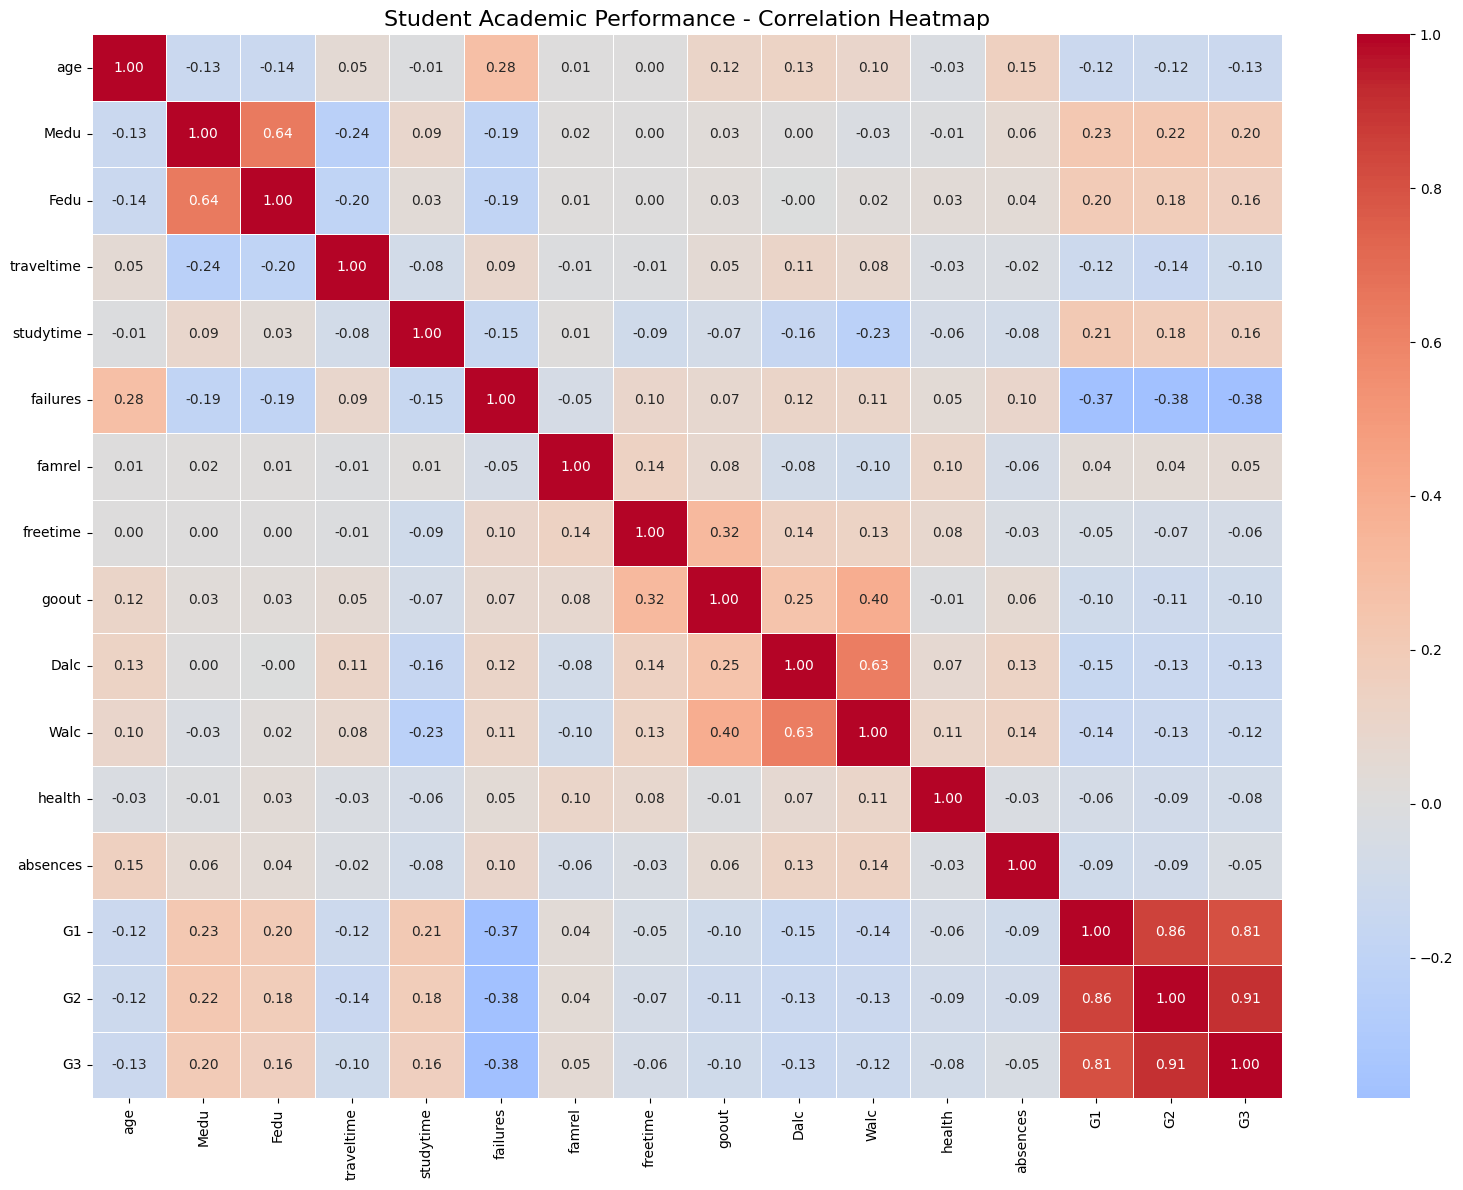

In [7]:

# Correlation heatmap

plt.figure(figsize=(16, 12))

correlation = education_df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Student Academic Performance - Correlation Heatmap",
          fontsize=16)

plt.tight_layout()
plt.show()


In [8]:

# Advanced outlier detection using IQR

columns_to_check = [
    "age",
    "absences",
    "studytime",
    "failures",
    "G1",
    "G2",
    "G3"
]

outlier_results = []

for col in columns_to_check:

    Q1 = education_df[col].quantile(0.25)
    Q3 = education_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = education_df[
        (education_df[col] < lower_bound) |
        (education_df[col] > upper_bound)
    ]

    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(education_df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)


,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,13.0,21.0,2,0.19
1,absences,-9.0,15.0,54,5.17
2,studytime,-0.5,3.5,62,5.94
3,failures,0.0,0.0,183,17.53
4,G1,3.0,19.0,1,0.10
5,G2,3.0,19.0,20,1.92
6,G3,4.0,20.0,54,5.17


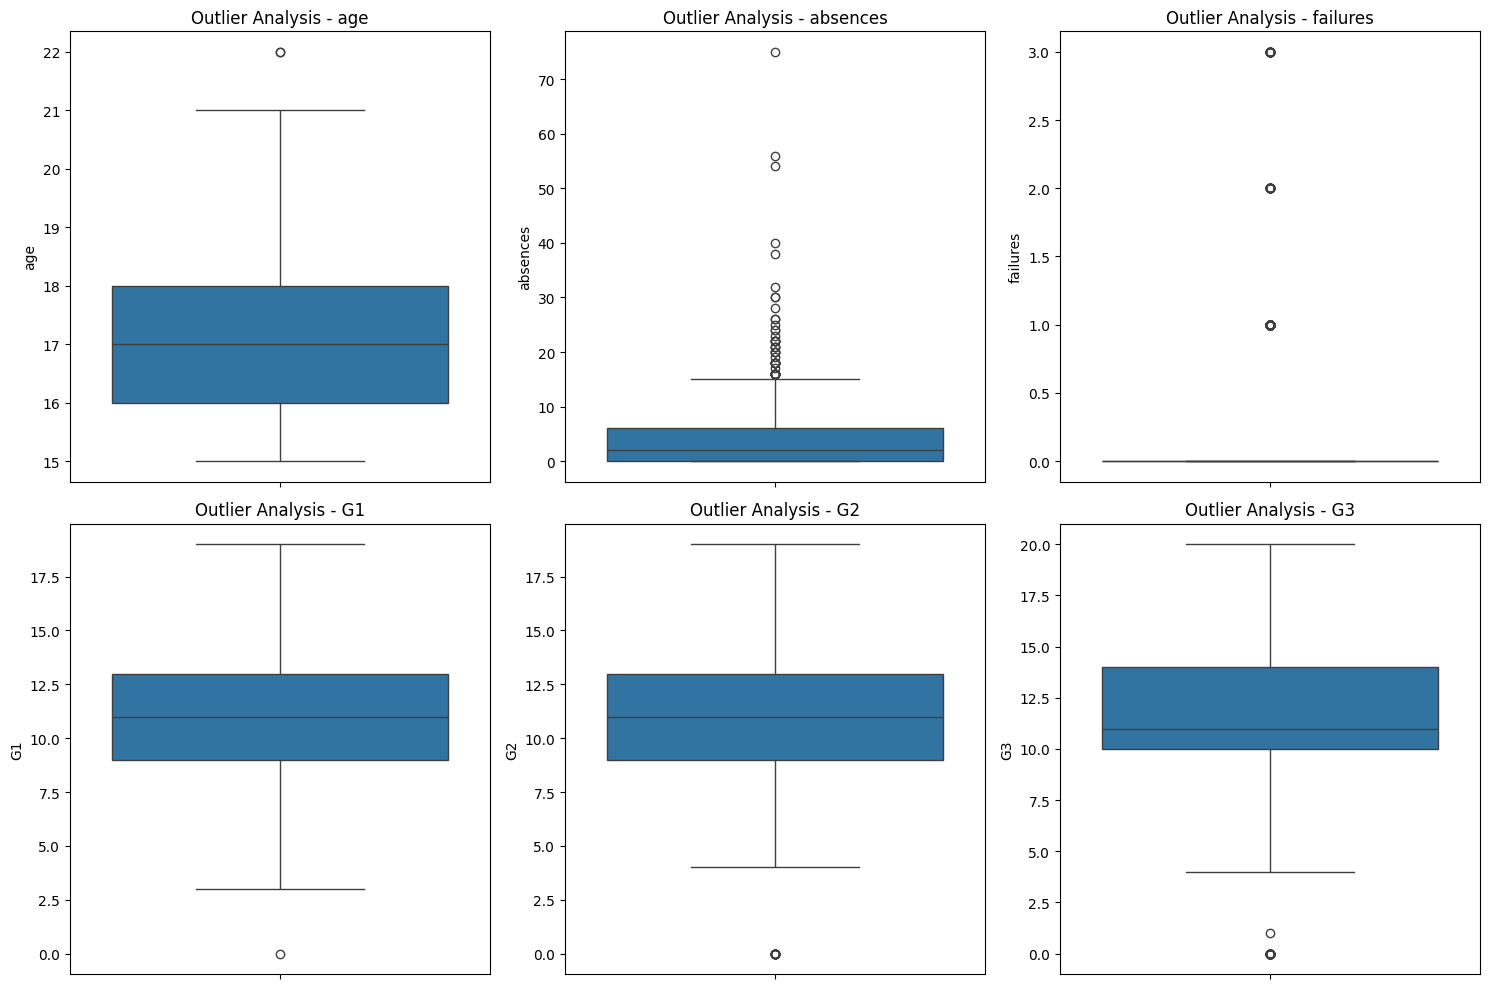

In [9]:

# Boxplot analysis of academic performance

import matplotlib.pyplot as plt
import seaborn as sns

columns_to_plot = [
    "age",
    "absences",
    "failures",
    "G1",
    "G2",
    "G3"
]

plt.figure(figsize=(15, 10))

for i, col in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(y=education_df[col])

    plt.title(f"Outlier Analysis - {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()


In [10]:

# Investigating students with high absences

high_absence_students = education_df[
    education_df["absences"] > 15
].copy()

print("Students with more than 15 absences:",
      len(high_absence_students))

print("\nAverage final grade:")
print(high_absence_students["G3"].mean().round(2))

print("\nPass / Fail distribution:")
print(
    high_absence_students["result"]
    .value_counts()
)

display(
    high_absence_students[
        ["subject", "age", "absences", "G1", "G2", "G3", "result"]
    ].sort_values("absences", ascending=False).head(15)
)


Students with more than 15 absences: 54

Average final grade:
10.31

Pass / Fail distribution:
result
Pass    34
Fail    20
Name: count, dtype: int64


,subject,age,absences,G1,G2,G3,result
276,Mathematics,18,75,10,9,9,Fail
183,Mathematics,17,56,9,9,8,Fail
74,Mathematics,16,54,11,12,11,Pass
315,Mathematics,19,40,13,11,11,Pass
307,Mathematics,19,38,8,9,8,Fail
592,Portuguese,17,32,14,13,14,Pass
280,Mathematics,17,30,8,8,8,Fail
607,Portuguese,17,30,14,15,16,Pass
205,Mathematics,17,28,10,9,9,Fail
651,Portuguese,18,26,7,8,8,Fail


In [11]:

# Compare high-absence students with other students

education_df["attendance_group"] = np.where(
    education_df["absences"] > 15,
    "High Absences",
    "15 or Fewer Absences"
)

attendance_comparison = (
    education_df.groupby("attendance_group")
    .agg(
        Students=("G3", "size"),
        Average_Absences=("absences", "mean"),
        Average_Final_Grade=("G3", "mean"),
        Pass_Rate=("result", lambda x: (x == "Pass").mean() * 100)
    )
    .round(2)
)

display(attendance_comparison)


,Students,Average_Absences,Average_Final_Grade,Pass_Rate
attendance_group,,,,
15 or Fewer Absences,990,3.43,11.40,78.79
High Absences,54,22.89,10.31,62.96


In [12]:

# Subject-wise academic performance comparison

subject_analysis = (
    education_df.groupby("subject")
    .agg(
        Students=("G3", "count"),
        Average_G1=("G1", "mean"),
        Average_G2=("G2", "mean"),
        Average_G3=("G3", "mean"),
        Average_Absences=("absences", "mean"),
        Pass_Rate=("result", lambda x: (x == "Pass").mean() * 100)
    )
    .round(2)
)

display(subject_analysis)


,Students,Average_G1,Average_G2,Average_G3,Average_Absences,Pass_Rate
subject,,,,,,
Mathematics,395,10.91,10.71,10.42,5.71,67.09
Portuguese,649,11.40,11.57,11.91,3.66,84.59


In [13]:

# Statistical significance test: Mathematics vs Portuguese

from scipy.stats import ttest_ind

math_grades = education_df.loc[
    education_df["subject"] == "Mathematics", "G3"
]

portuguese_grades = education_df.loc[
    education_df["subject"] == "Portuguese", "G3"
]

t_stat, p_value = ttest_ind(
    math_grades,
    portuguese_grades,
    equal_var=False
)

print("Welch's Independent Samples T-Test")
print("----------------------------------")
print(f"Mathematics mean: {math_grades.mean():.2f}")
print(f"Portuguese mean: {portuguese_grades.mean():.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("\nResult: Statistically significant difference.")
else:
    print("\nResult: No statistically significant difference.")


Welch's Independent Samples T-Test
----------------------------------
Mathematics mean: 10.42
Portuguese mean: 11.91
T-statistic: -5.6664
P-value: 0.000000

Result: Statistically significant difference.


In [14]:
# Effect Size Analysis - Cohen's d

import numpy as np

# Calculate group sizes
n1 = len(math_grades)
n2 = len(portuguese_grades)

# Calculate standard deviations
s1 = math_grades.std(ddof=1)
s2 = portuguese_grades.std(ddof=1)

# Calculate pooled standard deviation
pooled_std = np.sqrt(
    ((n1 - 1) * s1**2 + (n2 - 1) * s2**2)
    / (n1 + n2 - 2)
)

# Calculate Cohen's d
cohens_d = (
    math_grades.mean() - portuguese_grades.mean()
) / pooled_std

print("EFFECT SIZE ANALYSIS")
print("--------------------")
print(f"Cohen's d: {cohens_d:.4f}")

if abs(cohens_d) < 0.2:
    print("Effect: Negligible")
elif abs(cohens_d) < 0.5:
    print("Effect: Small")
elif abs(cohens_d) < 0.8:
    print("Effect: Medium")
else:
    print("Effect: Large")

EFFECT SIZE ANALYSIS
--------------------
Cohen's d: -0.3925
Effect: Small


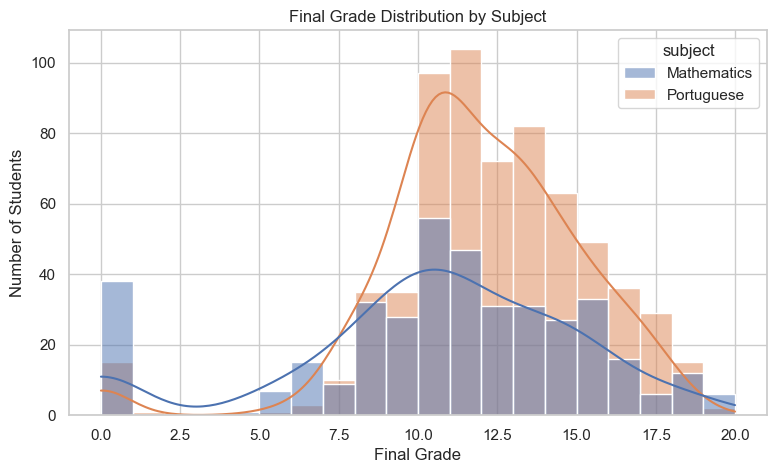

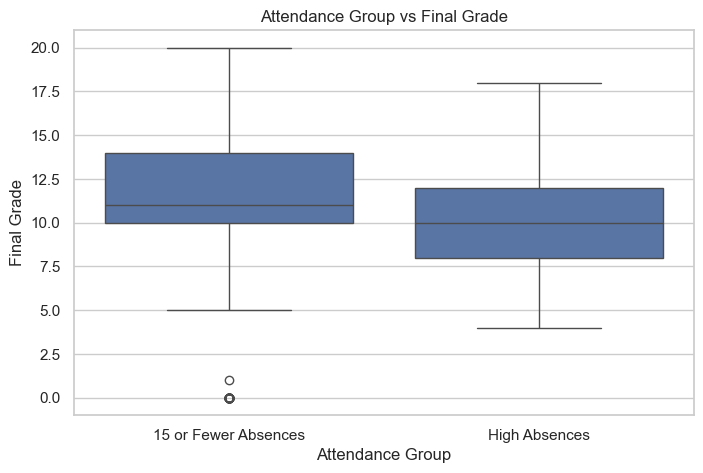

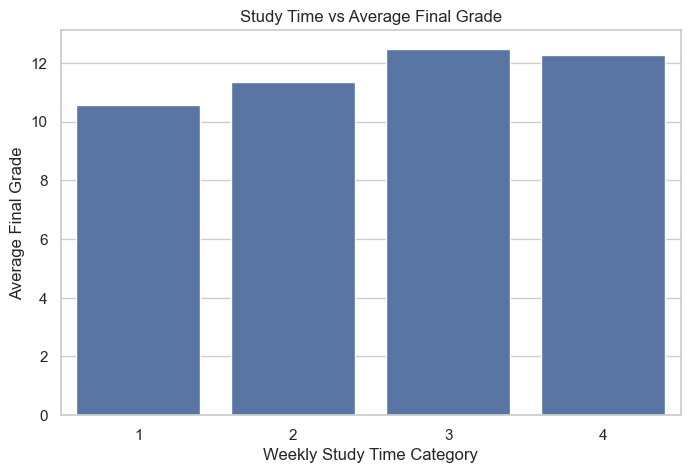

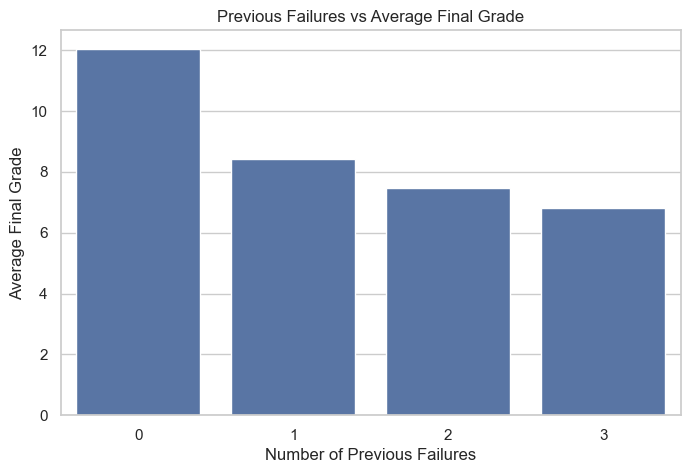

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Final grade distribution by subject
plt.figure(figsize=(9, 5))
sns.histplot(
    data=education_df,
    x="G3",
    hue="subject",
    bins=20,
    kde=True,
    multiple="layer"
)
plt.title("Final Grade Distribution by Subject")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()


# 2. Attendance vs final grade
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=education_df,
    x="attendance_group",
    y="G3"
)
plt.title("Attendance Group vs Final Grade")
plt.xlabel("Attendance Group")
plt.ylabel("Final Grade")
plt.show()


# 3. Study time vs final grade
plt.figure(figsize=(8, 5))
sns.barplot(
    data=education_df,
    x="studytime",
    y="G3",
    errorbar=None
)
plt.title("Study Time vs Average Final Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Average Final Grade")
plt.show()


# 4. Previous failures vs final grade
plt.figure(figsize=(8, 5))
sns.barplot(
    data=education_df,
    x="failures",
    y="G3",
    errorbar=None
)
plt.title("Previous Failures vs Average Final Grade")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Average Final Grade")
plt.show()

In [16]:
from pathlib import Path

# Create the Power BI output folder
OUTPUT_PATH = Path("../PowerBI")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# 1. Clean complete dataset
education_df.to_csv(
    OUTPUT_PATH / "Education_Cleaned_Data.csv",
    index=False
)

# 2. Subject performance summary
subject_summary = (
    education_df.groupby("subject")
    .agg(
        Students=("G3", "count"),
        Average_G1=("G1", "mean"),
        Average_G2=("G2", "mean"),
        Average_G3=("G3", "mean"),
        Average_Absences=("absences", "mean"),
        Pass_Rate=("result", lambda x: (x == "Pass").mean() * 100)
    )
    .round(2)
    .reset_index()
)

subject_summary.to_csv(
    OUTPUT_PATH / "Subject_Performance.csv",
    index=False
)

# 3. Attendance analysis
attendance_summary = (
    education_df.groupby("attendance_group")
    .agg(
        Students=("G3", "count"),
        Average_Absences=("absences", "mean"),
        Average_Final_Grade=("G3", "mean"),
        Pass_Rate=("result", lambda x: (x == "Pass").mean() * 100)
    )
    .round(2)
    .reset_index()
)

attendance_summary.to_csv(
    OUTPUT_PATH / "Attendance_Analysis.csv",
    index=False
)

# 4. Study time analysis
studytime_summary = (
    education_df.groupby("studytime")
    .agg(
        Students=("G3", "count"),
        Average_Final_Grade=("G3", "mean"),
        Pass_Rate=("result", lambda x: (x == "Pass").mean() * 100)
    )
    .round(2)
    .reset_index()
)

studytime_summary.to_csv(
    OUTPUT_PATH / "Study_Time_Analysis.csv",
    index=False
)

# 5. Previous failures analysis
failure_summary = (
    education_df.groupby("failures")
    .agg(
        Students=("G3", "count"),
        Average_Final_Grade=("G3", "mean"),
        Pass_Rate=("result", lambda x: (x == "Pass").mean() * 100)
    )
    .round(2)
    .reset_index()
)

failure_summary.to_csv(
    OUTPUT_PATH / "Previous_Failures_Analysis.csv",
    index=False
)

# 6. Correlation matrix
correlation_matrix = education_df.select_dtypes(
    include="number"
).corr().round(3)

correlation_matrix.to_csv(
    OUTPUT_PATH / "Correlation_Matrix.csv"
)

print("EXPORT COMPLETED!")
print("-----------------")

for file in OUTPUT_PATH.glob("*.csv"):
    print(file.name)

print("\nAll files saved in:", OUTPUT_PATH.resolve())

EXPORT COMPLETED!
-----------------
Attendance_Analysis.csv
Correlation_Matrix.csv
Education_Cleaned_Data.csv
Previous_Failures_Analysis.csv
Study_Time_Analysis.csv
Subject_Performance.csv

All files saved in: C:\Users\aadit\Desktop\Data_Analyst_Portfolio\Project_02_Education_Analytics\PowerBI
